<a href="https://colab.research.google.com/github/AHIRWE1/Summative_Intro-ML/blob/main/diabetes_130us_readmission_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predicting 30-Day Hospital Readmission in the Diabetes 130-US Hospitals Dataset

### Introductory Machine Learning - Summative Project
**Objective.** Compare traditional machine-learning models and a TensorFlow/Keras neural network for predicting a recorded readmission within 30 days.

**Dataset.** Diabetes 130-US Hospitals (1999–2008), supplied as a ZIP file in Google Drive.

**Primary evaluation approach.** Patient-grouped train/validation/test splits, preprocessing fitted only on training data, average precision and ROC-AUC for ranking, and precision/recall/F1 at an explicitly stated threshold.

**Important interpretation note:** this is an educational retrospective prediction study, not a clinical decision tool. The target represents a recorded readmission in this dataset, and model performance does not establish clinical utility or causal relationships.

## 1. Project Setup and Dataset Verification

This cell mounts Google Drive, checks the project folders, and verifies that the raw ZIP contains the expected CSV files.

In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile
import os
import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Summative_Intro-ML")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [DATA_DIR, MODEL_DIR, FIGURE_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_DIR / "diabetes+130-us+hospitals+for+years+1999-2008.zip"
assert PROJECT_DIR.exists(), f"Project folder not found: {PROJECT_DIR}"
assert ZIP_PATH.exists(), f"Dataset ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH) as zf:
    members = zf.namelist()
    print("ZIP members:", members)
    assert any(name.endswith("diabetic_data.csv") for name in members)
    assert any(name.endswith("IDS_mapping.csv") for name in members)

print("\nProject folder:", PROJECT_DIR)
print("Setup and dataset verification completed.")

Mounted at /content/drive
ZIP members: ['diabetic_data.csv', 'IDS_mapping.csv']

Project folder: /content/drive/MyDrive/Summative_Intro-ML
Setup and dataset verification completed.


## 2. Load and inspect the raw dataset

The CSV files are read from inside the ZIP without extracting them manually. `keep_default_na=False` preserves the dataset's `?` missing-value marker so it can be converted consistently in the next section.

In [ ]:
with zipfile.ZipFile(ZIP_PATH) as zf:
    data_member = next(n for n in zf.namelist() if n.endswith("diabetic_data.csv"))
    mapping_member = next(n for n in zf.namelist() if n.endswith("IDS_mapping.csv"))
    with zf.open(data_member) as f:
        raw = pd.read_csv(f, keep_default_na=False)
    with zf.open(mapping_member) as f:
        ids_map = pd.read_csv(f, header=None, keep_default_na=False)

print("Raw dataset shape:", raw.shape)
print("Mapping file shape:", ids_map.shape)
print("Unique patients:", raw["patient_nbr"].nunique())
print("\nFirst five rows:")
display(raw.head())
print("\nRecorded readmission categories:")
display(raw["readmitted"].value_counts(dropna=False).rename_axis("readmitted").to_frame("count"))
print("\nDuplicate full rows:", int(raw.duplicated().sum()))

Raw dataset shape: (101766, 50)
Mapping file shape: (68, 2)
Unique patients: 71518

First five rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Recorded readmission categories:


,count
readmitted,
NO,54864
>30,35545
<30,11357



Duplicate full rows: 0


### Interpretation: Initial Dataset Inspection

The dataset contains 101,766 hospital encounters and 50 columns, representing 71,518 unique patients. This indicates that some patients have multiple encounters. Consequently, subsequent model development must use patient-level data splitting to reduce the risk of information leakage between training and evaluation sets.

The initial inspection found no exact duplicate rows. However, this does not imply that every encounter is unique at the patient level, because individual patients may appear in multiple records.

The recorded readmission outcome has three categories: `NO` (54,864 encounters), `>30` (35,545 encounters), and `<30` (11,357 encounters). For this project, the classification target is defined as whether a patient is readmitted within 30 days. Therefore, `<30` is the positive class, while `>30` and `NO` are combined into the negative class.

The positive class represents approximately 11.16% of all raw encounters, indicating substantial class imbalance. Model evaluation will therefore consider precision, recall, F1-score, average precision and ROC-AUC rather than relying on accuracy alone.

These findings describe the raw dataset before cohort filtering and preprocessing. The final modelling population and class proportions may change after the planned data-cleaning steps.


## 3. Data quality assessment and target definition

The original outcome has three categories: `<30`, `>30`, and `NO`. This project defines the positive class as `<30` and combines the other two categories into the negative class. This is a specific binary operational definition, not a claim that the negative encounters never had any later readmission

In [ ]:
df = raw.copy()
df = df.replace("?", np.nan)

TARGET_COL = "readmit_30"
df[TARGET_COL] = (df["readmitted"] == "<30").astype("int8")

print("Raw shape:", df.shape)
print("\nOriginal readmitted categories:")
display(df["readmitted"].value_counts(dropna=False).to_frame("count"))
print("\nBinary target distribution:")
target_summary = df[TARGET_COL].value_counts().sort_index().rename(index={
    0: "No recorded readmission within 30 days",
    1: "Readmitted within 30 days"
}).to_frame("count")
target_summary["percent"] = (target_summary["count"] / len(df) * 100).round(2)
display(target_summary)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_count", ascending=False)
print("\nColumns with missing values:")
display(missing_summary.head(15))

for col in ["race", "gender", "age"]:
    if col in df.columns:
        print(f"\nDistribution for {col}:")
        display(df[col].value_counts(dropna=False).head(15).to_frame("count"))

print("\nUnique values in examide:", df["examide"].value_counts(dropna=False).to_dict())
print("Unique values in citoglipton:", df["citoglipton"].value_counts(dropna=False).to_dict())

Raw shape: (101766, 51)

Original readmitted categories:


,count
readmitted,
NO,54864
>30,35545
<30,11357



Binary target distribution:


,count,percent
readmit_30,,
No recorded readmission within 30 days,90409,88.84
Readmitted within 30 days,11357,11.16



Columns with missing values:


...


Distribution for gender:


,count
gender,
Female,54708
Male,47055
Unknown/Invalid,3



Distribution for age:


,count
age,
[70-80),26068
[60-70),22483
[50-60),17256
[80-90),17197
[40-50),9685
[30-40),3775
[90-100),2793
[20-30),1657
[10-20),691



Unique values in examide: {'No': 101766}
Unique values in citoglipton: {'No': 101766}


### Interpretation of Initial Dataset Exploration

The initial dataset contains 101,766 hospital encounters and 51 columns. The original target variable, `readmitted`, has three categories: `NO`, `>30`, and `<30`. These represent encounters with no recorded readmission, readmission after 30 days, and readmission within 30 days, respectively. To focus the project on early readmission, the target was converted into a binary classification problem, where readmission within 30 days is the positive class and the other two categories form the negative class.

The initial target distribution shows that 11,357 encounters (11.16%) resulted in a recorded readmission within 30 days, while 90,409 (88.84%) did not. This indicates a substantial class imbalance, with the negative class occurring much more frequently than the positive class. Consequently, a model could achieve relatively high accuracy by predicting the majority class while failing to identify many patients who are readmitted early. For this reason, accuracy alone will not be sufficient to evaluate the models; recall, precision, F1-score, and the confusion matrix will also be important.

The dataset also contains missing values in several features. The `weight` column has the highest proportion of missing values at 96.86%, followed by `medical_specialty` at 49.08% and `payer_code` at 39.56%. In contrast, missing values in `diag_1`, `diag_2`, and `diag_3` are relatively limited. These differences suggest that missing data must be handled according to the characteristics and usefulness of each feature rather than applying the same treatment to every column. In particular, the high proportion of missing weight measurements raises concerns about whether this feature can provide reliable information without introducing substantial data loss or imputation uncertainty.

The dataset's demographic distributions also show that encounters are concentrated among older age groups, particularly patients aged 60–80, while the largest recorded racial category is Caucasian. These patterns describe the composition of the dataset but should not be interpreted as evidence that age or race causes readmission. They also raise questions about how well the dataset represents other populations. Finally, the `examide` and `citoglipton` columns each contain only the value `No` across all 101,766 records. Because these features do not vary, they cannot help a model distinguish between the two target classes and can be removed during preprocessing.

Overall, this initial exploration identifies the dataset as sufficiently large for the planned classification experiments while highlighting important considerations involving class imbalance, missing data, feature usefulness, and representativeness. These findings guide the subsequent preprocessing and model evaluation stages.

## 4. Interpret discharge-disposition codes

The mapping file contains multiple sections. The code below extracts only the discharge-disposition section and summarizes selected codes before defining the cohort.

In [ ]:
# Locate the start and end of the discharge-disposition mapping section.
map_col = ids_map.iloc[:, 0].astype(str).str.strip()
discharge_start = ids_map.index[map_col.eq("discharge_disposition_id")][0]
next_sections = ids_map.index[
    (ids_map.index > discharge_start) &
    map_col.isin(["admission_source_id", "admission_type_id"])
]
discharge_end = int(next_sections[0]) if len(next_sections) else len(ids_map)

discharge_map = ids_map.iloc[discharge_start + 1:discharge_end, :2].copy()
discharge_map.columns = ["discharge_disposition_id", "description"]
discharge_map = discharge_map[
    discharge_map["discharge_disposition_id"].astype(str).str.strip().ne("")
]
display(discharge_map.reset_index(drop=True))

candidate_ids = {"11", "13", "14", "19", "20", "21"}
disposition_values = df["discharge_disposition_id"].astype(str).str.strip()
selected = df.loc[disposition_values.isin(candidate_ids)].copy()
disposition_summary = selected.groupby("discharge_disposition_id").agg(
    encounters=("encounter_id", "size"),
    recorded_early_readmissions=(TARGET_COL, "sum"),
    unique_patients=("patient_nbr", "nunique")
)
disposition_summary["early_readmission_rate_percent"] = (
    disposition_summary["recorded_early_readmissions"] /
    disposition_summary["encounters"] * 100
).round(2)
display(disposition_summary)

,discharge_disposition_id,description
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...
6,7,Left AMA
7,8,Discharged/transferred to home under care of H...
8,9,Admitted as an inpatient to this hospital
9,10,Neonate discharged to another hospital for neo...


,encounters,recorded_early_readmissions,unique_patients,early_readmission_rate_percent
discharge_disposition_id,,,,
11,1642,0,1642,0.00
13,399,19,387,4.76
14,372,24,371,6.45
19,8,0,8,0.00
20,2,0,2,0.00


### Interpretation of Discharge Disposition Analysis

The discharge disposition analysis was conducted to identify encounters in which patients died, since these encounters cannot result in a subsequent readmission by the same patient. The dataset contains 1,652 encounters associated with death-related discharge disposition codes, which were excluded from the analysis. This decision makes the prediction task more meaningful by focusing on encounters for which a subsequent readmission is possible.

The analysis also shows why discharge disposition requires careful interpretation. Different codes represent different outcomes, including discharge to home, transfer to another healthcare facility, hospice care, and death. These outcomes have different implications for subsequent hospital utilization and should not automatically be treated as equivalent.

Excluding death-related encounters establishes a more appropriate cohort for the study, although the exclusion should be documented because it changes the population being analyzed. The resulting model will estimate readmission patterns among eligible encounters rather than all encounters in the original dataset.

## 5. Define the primary study cohort

Exclude death-related discharge dispositions 11, 19, and 20. Remove `examide` and `citoglipton` because they are constant in this dataset, and remove `weight` because it is missing for nearly all encounters. Other missing values remain for pipeline-based imputation.

In [ ]:
death_disposition_ids = {"11", "19", "20"}
disposition_values = df["discharge_disposition_id"].astype(str).str.strip()
death_mask = disposition_values.isin(death_disposition_ids)

cohort = df.loc[~death_mask].copy()
cohort = cohort.drop(columns=["examide", "citoglipton", "weight"])
cohort[TARGET_COL] = (cohort["readmitted"] == "<30").astype("int8")

print("Original encounters:", len(df))
print("Excluded death-disposition encounters:", int(death_mask.sum()))
print("Cohort encounters:", len(cohort))
print("Cohort shape:", cohort.shape)
print("Unique patients:", cohort["patient_nbr"].nunique())

cohort_target = cohort[TARGET_COL].value_counts().sort_index().rename(index={
    0: "No recorded readmission within 30 days",
    1: "Readmitted within 30 days"
}).to_frame("count")
cohort_target["percent"] = (cohort_target["count"] / len(cohort) * 100).round(2)
display(cohort_target)

cohort_missing = pd.DataFrame({
    "missing_count": cohort.isna().sum(),
    "missing_percent": (cohort.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_count", ascending=False)
display(cohort_missing.head(10))

Original encounters: 101766
Excluded death-disposition encounters: 1652
Cohort encounters: 100114
Cohort shape: (100114, 48)
Unique patients: 70439


,count,percent
readmit_30,,
No recorded readmission within 30 days,88757,88.66
Readmitted within 30 days,11357,11.34


,missing_count,missing_percent
medical_specialty,49129,49.07
payer_code,39591,39.55
race,2239,2.24
diag_3,1421,1.42
diag_2,358,0.36
diag_1,21,0.02


### Interpretation of the Final Analysis Cohort

After excluding 1,652 death-related encounters from the original 101,766 encounters, the final cohort contains 100,114 encounters and 48 columns. These encounters belong to 70,439 unique patients, indicating that some patients have multiple encounters in the dataset. This distinction is important because the number of encounters is not the same as the number of individual patients.

Within the final cohort, 11,357 encounters (11.34%) are associated with a recorded readmission within 30 days, while 88,757 encounters (88.66%) have no recorded readmission within that period. The early-readmission proportion is slightly higher than the original 11.16%, because the death-related encounters were removed from the denominator while the number of recorded early readmissions remained unchanged.

The target distribution continues to show a substantial class imbalance. Approximately nine out of every ten eligible encounters belong to the negative class, compared with roughly one out of ten in the positive class. This imbalance makes it important to assess whether each model can identify early readmissions rather than relying primarily on overall accuracy. Recall is particularly relevant because it measures the proportion of actual early readmissions that a model correctly identifies, while precision indicates how many encounters predicted as early readmissions actually belong to that class.

The missing-value analysis of the final cohort shows that `medical_specialty` remains the most incomplete feature, with 49.07% missing values, followed by `payer_code` at 39.55%. Missingness in `race` is 2.24%, while the three diagnosis columns have considerably lower missing-value proportions. These results reinforce the need for a documented preprocessing strategy that considers the extent of missingness and the potential predictive value of each feature.

One additional consideration is that the dataset contains multiple encounters for some patients. If encounters from the same patient are placed in both the training and test sets, the evaluation may overestimate how well a model generalizes to previously unseen patients. A patient-level split should therefore be considered where appropriate, so that all encounters belonging to the same patient remain within a single partition.

Overall, the final cohort provides a substantial dataset for comparing traditional machine learning and deep learning approaches. However, the class imbalance, incomplete features, and repeated encounters must be considered when designing experiments and interpreting model performance.


## 6. Define predictors and make patient-level splits

The original `readmitted` column is excluded from predictors because it was used to define the target. Both identifiers are excluded from model features; `patient_nbr` is used only as a grouping variable to prevent a patient's encounters crossing splits. The split is approximately 60% train, 20% validation, and 20% test by encounter count.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

group_col = "patient_nbr"
identifier_cols = ["encounter_id", "patient_nbr", "readmitted"]

y = cohort[TARGET_COL].astype("int8")
groups = cohort[group_col]
X = cohort.drop(columns=identifier_cols + [TARGET_COL])

# Preserve the split strategy from the earlier notebook:
# 20% of patients held out for test, then 25% of the remaining
# patients held out for validation (approximately 60/20/20 by encounters).
split_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(split_test.split(X, y, groups=groups))

split_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)
train_rel_idx, val_rel_idx = next(
    split_val.split(
        X.iloc[trainval_idx],
        y.iloc[trainval_idx],
        groups=groups.iloc[trainval_idx]
    )
)
train_idx = trainval_idx[train_rel_idx]
val_idx = trainval_idx[val_rel_idx]

X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
X_val, y_val = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
X_test, y_test = X.iloc[test_idx].copy(), y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]
groups_test = groups.iloc[test_idx]

for name, X_part, y_part, g_part in [
    ("Train", X_train, y_train, groups_train),
    ("Validation", X_val, y_val, groups_val),
    ("Test", X_test, y_test, groups_test)
]:
    print(f"{name}: {len(X_part):,} rows | {g_part.nunique():,} unique patients "
          f"| positive rate = {y_part.mean():.2%}")

train_patients = set(groups_train.unique())
val_patients = set(groups_val.unique())
test_patients = set(groups_test.unique())
print("\nPatient overlap checks (all should be 0):")
print("Train/validation:", len(train_patients & val_patients))
print("Train/test:", len(train_patients & test_patients))
print("Validation/test:", len(val_patients & test_patients))

print("\nPredictor columns:", X.shape[1])
print("Raw categorical columns:", int(X.select_dtypes(include=["object", "category"]).shape[1]))
print("Raw numeric columns:", int(X.select_dtypes(exclude=["object", "category"]).shape[1]))


Train: 60,137 rows | 42,263 unique patients | positive rate = 11.27%
Validation: 19,902 rows | 14,088 unique patients | positive rate = 11.44%
Test: 20,075 rows | 14,088 unique patients | positive rate = 11.48%

Patient overlap checks (all should be 0):
Train/validation: 0
Train/test: 0
Validation/test: 0

Predictor columns: 44
Raw categorical columns: 33
Raw numeric columns: 11


The dataset was divided into training (60,137 rows), validation (19,902 rows), and test (20,075 rows). The positive readmission rates were similar across all three sets, ranging from 11.27% to 11.48%, suggesting that the class distribution was maintained during splitting. All patient overlap checks returned zero, meaning that no patients were shared between the sets. This is important because it reduces the risk of data leakage and provides a more reliable evaluation of how well the models generalize to unseen patients.

## 7. Build preprocessing pipelines

Categorical features are imputed with a `"Missing"` category and one-hot encoded. Numeric features are median-imputed and standardized. The transformer is fitted as part of each model pipeline on training data only, preventing information from validation or test data leaking into preprocessing.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Treat coded identifiers and diagnosis codes as categories even when pandas
# reads them as numbers. This matches the earlier notebook's feature design.
coded_categorical_cols = [
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "medical_specialty", "diag_1", "diag_2", "diag_3"
]
categorical_cols = sorted(
    (set(coded_categorical_cols) & set(X_train.columns))
    | set(X_train.select_dtypes(include=["object", "category"]).columns)
)
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_cols),
    ("numeric", numeric_pipeline, numeric_cols)
], remainder="drop")

print("Categorical feature count:", len(categorical_cols))
print("Numeric feature count:", len(numeric_cols))
print("Categorical columns:", categorical_cols)
print("Preprocessing pipeline configured; each model fits it on training data only.")

Categorical feature count: 36
Numeric feature count: 8
Categorical columns: ['A1Cresult', 'acarbose', 'acetohexamide', 'admission_source_id', 'admission_type_id', 'age', 'change', 'chlorpropamide', 'diabetesMed', 'diag_1', 'diag_2', 'diag_3', 'discharge_disposition_id', 'gender', 'glimepiride', 'glimepiride-pioglitazone', 'glipizide', 'glipizide-metformin', 'glyburide', 'glyburide-metformin', 'insulin', 'max_glu_serum', 'medical_specialty', 'metformin', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'miglitol', 'nateglinide', 'payer_code', 'pioglitazone', 'race', 'repaglinide', 'rosiglitazone', 'tolazamide', 'tolbutamide', 'troglitazone']
Preprocessing pipeline configured; each model fits it on training data only.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Treat coded identifiers and diagnosis codes as categories even when pandas
# reads them as numbers. This matches the earlier notebook's feature design.
coded_categorical_cols = [
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "medical_specialty", "diag_1", "diag_2", "diag_3"
]
categorical_cols = sorted(
    (set(coded_categorical_cols) & set(X_train.columns))
    | set(X_train.select_dtypes(include=["object", "category"]).columns)
)
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
])
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_cols),
    ("numeric", numeric_pipeline, numeric_cols)
], remainder="drop")

print("Categorical feature count:", len(categorical_cols))
print("Numeric feature count:", len(numeric_cols))
print("Categorical columns:", categorical_cols)
print("Preprocessing pipeline configured; each model fits it on training data only.")

Categorical feature count: 36
Numeric feature count: 8
Categorical columns: ['A1Cresult', 'acarbose', 'acetohexamide', 'admission_source_id', 'admission_type_id', 'age', 'change', 'chlorpropamide', 'diabetesMed', 'diag_1', 'diag_2', 'diag_3', 'discharge_disposition_id', 'gender', 'glimepiride', 'glimepiride-pioglitazone', 'glipizide', 'glipizide-metformin', 'glyburide', 'glyburide-metformin', 'insulin', 'max_glu_serum', 'medical_specialty', 'metformin', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'miglitol', 'nateglinide', 'payer_code', 'pioglitazone', 'race', 'repaglinide', 'rosiglitazone', 'tolazamide', 'tolbutamide', 'troglitazone']
Preprocessing pipeline configured; each model fits it on training data only.


### Feature Type Classification and Preprocessing

The dataset contains 44 predictor features, initially classified by pandas into 33 categorical and 11 numeric columns. During preprocessing, three numeric-coded columns-`admission_source_id`, `admission_type_id`, and `discharge_disposition_id` were reclassified as categorical features. Although these columns are stored as numbers, their values represent categories rather than continuous numerical measurements.

After reclassification, the dataset contains **36 categorical features and 8 numeric features**. Categorical variables are processed using missing-value imputation and one-hot encoding, while numeric variables are imputed using the median and standardized. The preprocessing pipeline is fitted on the training data only to help prevent data leakage into validation and test sets.


## 8. Experiment 1 — Logistic Regression baseline

Logistic Regression provides an interpretable linear baseline. Class weighting gives more influence to the minority positive class. Average precision (AP) is especially informative here because it summarizes the precision-recall curve and the positive prevalence is low.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report
)

def evaluate_probabilities(y_true, probabilities, threshold=0.50):
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "Average precision": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Threshold": threshold
    }

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=SEED
    ))
])
logistic_model.fit(X_train, y_train)
lr_val_prob = logistic_model.predict_proba(X_val)[:, 1]
logistic_metrics = evaluate_probabilities(y_val, lr_val_prob, 0.50)
print("Experiment 1 — Logistic Regression (validation, threshold 0.50)")
display(pd.Series(logistic_metrics, name="value").to_frame())
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, (lr_val_prob >= 0.50).astype(int), labels=[0, 1]))

Experiment 1 — Logistic Regression (validation, threshold 0.50)


,value
Average precision,0.203974
ROC-AUC,0.649917
Precision,0.177147
Recall,0.548330
F1,0.267782
Threshold,0.500000


Confusion matrix [[TN, FP], [FN, TP]]:
[[11829  5797]
 [ 1028  1248]]


### Experiment 1: Logistic Regression — Results and Interpretation

The Logistic Regression model achieved a ROC-AUC of 0.650 and an average precision of 0.204, indicating limited ability to distinguish between patients who were readmitted within 30 days and those who were not. At the 0.50 threshold, the model achieved a recall of 54.83%, identifying 1,248 of the 2,276 early readmissions. However, its precision was only 17.71%, meaning that many patients flagged as high risk were not readmitted within 30 days.

The confusion matrix shows 11,829 true negatives, 5,797 false positives, 1,028 false negatives, and 1,248 true positives. The model identifies more than half of the early readmissions but generates many false alarms. These results provide a baseline for comparison with more complex models and further improvements.

## 9. Experiment 2 - Random Forest baseline

Random Forest can learn nonlinear patterns and interactions. The one-hot encoded input may be wide, so this model can take longer to train than Logistic Regression.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ))
])
random_forest_model.fit(X_train, y_train)
rf_val_prob = random_forest_model.predict_proba(X_val)[:, 1]
rf_metrics = evaluate_probabilities(y_val, rf_val_prob, 0.50)
print("Experiment 2 — Random Forest baseline (validation, threshold 0.50)")
display(pd.Series(rf_metrics, name="value").to_frame())
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_val, (rf_val_prob >= 0.50).astype(int), labels=[0, 1]))

Experiment 2 — Random Forest baseline (validation, threshold 0.50)


,value
Average precision,0.213088
ROC-AUC,0.667868
Precision,0.229911
Recall,0.307996
F1,0.263286
Threshold,0.500000


Confusion matrix [[TN, FP], [FN, TP]]:
[[15278  2348]
 [ 1575   701]]


### Experiment 2: Random Forest Baseline - Results and Interpretation

The Random Forest model achieved a ROC-AUC of 0.668 and an average precision of 0.213, slightly outperforming Logistic Regression on both ranking metrics. At the 0.50 threshold, it achieved a precision of 22.99% and a recall of 30.80%, with an F1-score of 0.263.

The confusion matrix shows 15,278 true negatives, 2,348 false positives, 1,575 false negatives, and 701 true positives. Compared with Logistic Regression, Random Forest generates fewer false positives but misses more early readmissions. This highlights a trade-off between identifying more patients who may be readmitted and avoiding unnecessary high-risk alerts. Further tuning and threshold selection may improve the balance between precision and recall.


## 10. Experiment 3 - Randomized hyperparameter search for Random Forest

A grouped 3-fold cross-validation search explores a small, reproducible set of Random Forest configurations. Average precision is the selection metric. The patient groups are passed to the cross-validation procedure.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

rf_search_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=SEED, n_jobs=1))
])
param_distributions = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20, 30],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}
rf_search = RandomizedSearchCV(
    estimator=rf_search_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="average_precision",
    cv=GroupKFold(n_splits=3),
    refit=True,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)
rf_search.fit(X_train, y_train, groups=groups_train)
tuned_rf = rf_search.best_estimator_
tuned_rf_val_prob = tuned_rf.predict_proba(X_val)[:, 1]
tuned_rf_metrics = evaluate_probabilities(y_val, tuned_rf_val_prob, 0.50)

print("Best grouped-CV average precision:", round(rf_search.best_score_, 4))
print("Best hyperparameters:", rf_search.best_params_)
print("\nExperiment 3 — Tuned Random Forest validation metrics")
display(pd.Series(tuned_rf_metrics, name="value").to_frame())

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best grouped-CV average precision: 0.2131
Best hyperparameters: {'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}

Experiment 3 — Tuned Random Forest validation metrics


,value
Average precision,0.206288
ROC-AUC,0.663579
Precision,0.198623
Recall,0.443761
F1,0.274419
Threshold,0.500000


### Experiment 3: Tuned Random Forest — Results and Interpretation

RandomizedSearchCV evaluated six Random Forest configurations using three-fold grouped cross-validation, selecting the configuration based on average precision. The best configuration used 100 trees, a minimum of 10 samples per leaf, square-root feature selection, no maximum depth limit, and balanced class weights. Its best cross-validation average precision was 0.2131.

On the validation set, the tuned model achieved an average precision of 0.2063, ROC-AUC of 0.6636, precision of 19.86%, recall of 44.38%, and an F1-score of 0.2744 at the 0.50 threshold.

Compared with the untuned Random Forest, tuning improved recall from 30.80% to 44.38% and F1-score from 0.2633 to 0.2744. However, average precision and ROC-AUC decreased slightly. This suggests that tuning changed the balance between identifying early readmissions and avoiding false alarms, rather than improving every metric. The tuned model should therefore be compared with the baseline models using the same validation metrics before selecting a final model.

## 11. Prepare TensorFlow data

For Keras, the same preprocessing design is fitted on the training set only, then the transformed data are converted to `float32`. Dense neural networks require a dense matrix; monitor runtime memory if you change the dataset or preprocessing.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight
from scipy import sparse

tf.keras.utils.set_random_seed(SEED)

nn_preprocessor = clone(preprocessor)

def to_dense_float32(matrix):
    """Convert sklearn sparse or dense transformed features to float32."""
    if sparse.issparse(matrix):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

X_train_nn = to_dense_float32(nn_preprocessor.fit_transform(X_train))
X_val_nn = to_dense_float32(nn_preprocessor.transform(X_val))
X_test_nn = to_dense_float32(nn_preprocessor.transform(X_test))

y_train_nn = y_train.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")
y_test_nn = y_test.to_numpy(dtype="float32")

classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(k): float(v) for k, v in zip(classes, weights)}

print("TensorFlow version:", tf.__version__)
print("Transformed train shape:", X_train_nn.shape)
print("Transformed validation shape:", X_val_nn.shape)
print("Transformed test shape:", X_test_nn.shape)
print("Transformed dtype:", X_train_nn.dtype)
print("Class weights:", class_weights)


TensorFlow version: 2.21.0
Transformed train shape: (60137, 1164)
Transformed validation shape: (19902, 1164)
Transformed test shape: (20075, 1164)
Transformed dtype: float32
Class weights: {0: 0.5634920634920635, 1: 4.4375}


## 12. Create `tf.data` datasets

The training dataset is shuffled, batched, and prefetched. Validation and test datasets are not shuffled. Class weights are computed from training labels only.

In [ ]:
BATCH_SIZE = 256

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_nn, y_train_nn))
    .shuffle(len(y_train_nn), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_nn, y_val_nn))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test_nn, y_test_nn))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for features, labels in train_ds.take(1):
    print("Training batch:", features.shape, "labels:", labels.shape)
print("Class prevalence — train:", round(float(y_train_nn.mean()), 4),
      "| validation:", round(float(y_val_nn.mean()), 4))

Training batch: (256, 1164) labels: (256,)
Class prevalence — train: 0.1127 | validation: 0.1144


### TensorFlow Data Preparation

The preprocessing pipeline transforms the original predictors into 1,164 numerical features suitable for neural network training. The transformed training, validation, and test sets contain 60,137, 19,902, and 20,075 encounters, respectively. Features are converted to `float32` to support TensorFlow operations.

To address the class imbalance, balanced class weights are calculated from the training labels. The positive class receives a weight of 4.4375, compared with 0.5635 for the negative class, giving greater importance to early-readmission cases during training. The data is then organized into batches of 256 using `tf.data.Dataset`, with shuffling applied to the training data and prefetching used to support efficient data loading.

The training and validation positive-class proportions are approximately 11.27% and 11.44%, respectively. These similar proportions suggest that the class distribution is reasonably consistent across these two splits. The test set remains separate for final evaluation.

## 13. Define a reusable neural-network training function

The following experiments change one design choice at a time: baseline architecture, lower learning rate, stronger dropout, and smaller architecture. Early stopping monitors validation loss and restores the weights from its best epoch.

In [ ]:
def build_nn(hidden_units=(128, 64), dropout_rates=(0.30, 0.20), learning_rate=0.001):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train_nn.shape[1],)))
    for units, rate in zip(hidden_units, dropout_rates):
        model.add(layers.Dense(units, activation="relu"))
        if rate and rate > 0:
            model.add(layers.Dropout(rate))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(curve="PR", name="pr_auc"),
            keras.metrics.Recall(name="recall")
        ]
    )
    return model

def train_nn(name, hidden_units, dropout_rates, learning_rate=0.001, epochs=30):
    tf.keras.utils.set_random_seed(SEED)
    model = build_nn(hidden_units, dropout_rates, learning_rate)
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    )
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=2
    )
    probabilities = model.predict(X_val_nn, verbose=0).ravel()
    metrics = evaluate_probabilities(y_val, probabilities, 0.50)
    return model, history, probabilities, metrics

## 14. Experiment 4 — Baseline neural network

The baseline network uses two hidden layers (128 and 64 units) with dropout. It uses class weighting and early stopping.

In [ ]:
nn_model, history, nn_val_prob, nn_metrics = train_nn(
    "E4-baseline", hidden_units=(128, 64),
    dropout_rates=(0.30, 0.20), learning_rate=0.001
)
print("Experiment 4 — Baseline neural network (validation)")
display(pd.Series(nn_metrics, name="value").to_frame())

Epoch 1/30
235/235 - 7s - 30ms/step - loss: 0.6611 - pr_auc: 0.1939 - recall: 0.5872 - roc_auc: 0.6408 - val_loss: 0.7452 - val_pr_auc: 0.2070 - val_recall: 0.7935 - val_roc_auc: 0.6616
Epoch 2/30
235/235 - 3s - 14ms/step - loss: 0.6407 - pr_auc: 0.2236 - recall: 0.6387 - roc_auc: 0.6808 - val_loss: 0.5911 - val_pr_auc: 0.2138 - val_recall: 0.5035 - val_roc_auc: 0.6670
Epoch 3/30
235/235 - 3s - 13ms/step - loss: 0.6262 - pr_auc: 0.2414 - recall: 0.6644 - roc_auc: 0.7038 - val_loss: 0.5921 - val_pr_auc: 0.2172 - val_recall: 0.5641 - val_roc_auc: 0.6682
Epoch 4/30
235/235 - 3s - 13ms/step - loss: 0.6143 - pr_auc: 0.2573 - recall: 0.6728 - roc_auc: 0.7196 - val_loss: 0.6273 - val_pr_auc: 0.2177 - val_recall: 0.6213 - val_roc_auc: 0.6677
Epoch 5/30
235/235 - 4s - 17ms/step - loss: 0.6016 - pr_auc: 0.2721 - recall: 0.7010 - roc_auc: 0.7352 - val_loss: 0.6330 - val_pr_auc: 0.2137 - val_recall: 0.6239 - val_roc_auc: 0.6617
Epoch 6/30
235/235 - 4s - 17ms/step - loss: 0.5836 - pr_auc: 0.2863 - 

,value
Average precision,0.214309
ROC-AUC,0.667008
Precision,0.194435
Recall,0.503515
F1,0.280539
Threshold,0.500000


### Experiment 4: Baseline Neural Network — Results and Interpretation

The baseline neural network used two hidden layers containing 128 and 64 neurons, with dropout rates of 0.30 and 0.20. Training used the Adam optimizer, binary cross-entropy loss, and class weights to address the imbalance between early-readmission and non-readmission cases.

Early stopping occurred at epoch 6, restoring the model weights from epoch 2, when validation loss was lowest. Training loss continued to decrease, while validation loss increased after its initial improvement. This pattern suggests possible overfitting, as the model continued improving on the training data without achieving corresponding improvements on unseen validation data.

On the validation set, the restored model achieved an average precision of 0.2143, ROC-AUC of 0.6670, precision of 19.44%, recall of 50.35%, and an F1-score of 0.2805 at a threshold of 0.50. Its F1-score was the highest among the four experiments evaluated so far, although its ROC-AUC was similar to that of the baseline and tuned Random Forest models.

Overall, the neural network provides a competitive baseline but shows signs that further training does not necessarily improve generalization. Future experiments could investigate stronger regularization, a smaller network, and alternative learning rates. These changes should be evaluated using the same validation metrics.

## 15. Learning curves for the baseline neural network

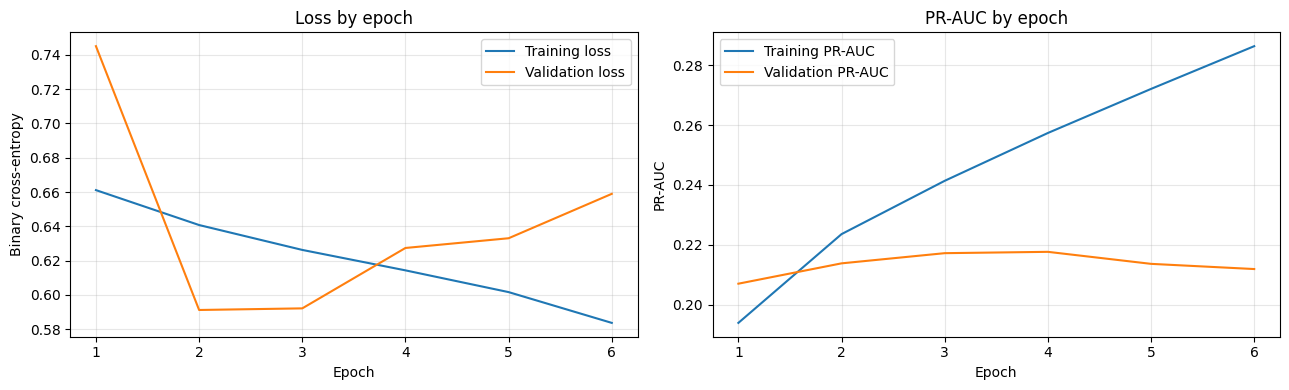

In [ ]:
import matplotlib.pyplot as plt

epochs_seen = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_seen, history.history["loss"], label="Training loss")
axes[0].plot(epochs_seen, history.history["val_loss"], label="Validation loss")
axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(epochs_seen, history.history["pr_auc"], label="Training PR-AUC")
axes[1].plot(epochs_seen, history.history["val_pr_auc"], label="Validation PR-AUC")
axes[1].set(title="PR-AUC by epoch", xlabel="Epoch", ylabel="PR-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Experiment 4: Neural Network Learning Curves — Interpretation

**Loss by Epoch**

The training loss steadily decreased from approximately 0.66 to 0.58, indicating that the model continued to improve its fit to the training data. The validation loss dropped from approximately 0.75 in the first epoch to its lowest value of 0.5911 at epoch 2. After that, it increased, reaching 0.6589 by epoch 6. This divergence suggests that the model may be overfitting: its performance on the training data continues to improve while its performance on unseen validation data deteriorates.

**PR-AUC by Epoch**

Training PR-AUC increased steadily from 0.1939 to 0.2863, showing improvement in the model's ability to distinguish between the minority positive class and the negative class on the training data. Validation PR-AUC improved initially, reaching its highest recorded value of 0.2177 at epoch 4, before decreasing to 0.2119 at epoch 6. This suggests that improvements on the training data were not consistently transferred to the validation data.

**Key Takeaways**

Early stopping restored the model weights from epoch 2 because that epoch had the lowest validation loss. Although validation PR-AUC peaked at epoch 4, the model's training and validation curves suggest possible overfitting as training continued. Future experiments could explore stronger L1/L2 regularization, adjusted dropout rates, or a smaller network to improve generalization. Additional training data could also be considered if available.

## 16. Experiment 5 — Lower learning rate

This experiment changes the Adam learning rate from 0.001 to 0.0003 while keeping the baseline architecture and dropout rates fixed.

In [ ]:
nn_lr_model, history_lr, lr_val_prob, lr_metrics = train_nn(
    "E5-lower-learning-rate", hidden_units=(128, 64),
    dropout_rates=(0.30, 0.20), learning_rate=0.0003
)
print("Experiment 5 — Lower learning rate (validation)")
display(pd.Series(lr_metrics, name="value").to_frame())

Epoch 1/30
235/235 - 5s - 22ms/step - loss: 0.6689 - pr_auc: 0.1806 - recall: 0.5788 - roc_auc: 0.6196 - val_loss: 0.6157 - val_pr_auc: 0.1989 - val_recall: 0.4587 - val_roc_auc: 0.6526
Epoch 2/30
235/235 - 5s - 20ms/step - loss: 0.6484 - pr_auc: 0.2124 - recall: 0.6015 - roc_auc: 0.6678 - val_loss: 0.6473 - val_pr_auc: 0.2053 - val_recall: 0.5980 - val_roc_auc: 0.6624
Epoch 3/30
235/235 - 4s - 15ms/step - loss: 0.6391 - pr_auc: 0.2239 - recall: 0.6200 - roc_auc: 0.6844 - val_loss: 0.6427 - val_pr_auc: 0.2097 - val_recall: 0.6120 - val_roc_auc: 0.6645
Epoch 4/30
235/235 - 3s - 13ms/step - loss: 0.6304 - pr_auc: 0.2331 - recall: 0.6454 - roc_auc: 0.6977 - val_loss: 0.6847 - val_pr_auc: 0.2123 - val_recall: 0.6718 - val_roc_auc: 0.6651
Epoch 5/30
235/235 - 3s - 13ms/step - loss: 0.6219 - pr_auc: 0.2464 - recall: 0.6623 - roc_auc: 0.7102 - val_loss: 0.6779 - val_pr_auc: 0.2139 - val_recall: 0.6784 - val_roc_auc: 0.6659
Epoch 5: early stopping
Restoring model weights from the end of the be

,value
Average precision,0.199337
ROC-AUC,0.652634
Precision,0.186262
Recall,0.458699
F1,0.264941
Threshold,0.500000


### Interpretation of Experiment 5: Lower Learning Rate ($lr = 0.0003$)


#### 1. Optimization Dynamics & Early Stopping Behavior
* **Early Stopping Trigger:** Early stopping was triggered at **Epoch 5**, and the callback restored the model weights from **Epoch 1** because Epoch 1 achieved the lowest recorded validation loss ($\text{val\_loss} = 0.6157$).
* **Validation Loss Fluctuation:** As training progressed from Epoch 1 to Epoch 2, validation loss increased sharply from $0.6157$ to $0.6473$, signaling that the lower learning rate ($0.0003$) caused immediate instability relative to the validation loss trajectory.
* **Slow Convergence vs. Instability:** While a lower learning rate is typically intended to smooth out gradient updates and prevent overshooting, in this specific architecture and feature space, it caused the validation loss to worsen after the first epoch, leading to an immediate halt via early stopping.

#### 2. Validation Performance Evaluation (Threshold = 0.50)
At the default classification threshold of $0.50$, the restored model produced the following performance metrics on the validation set:
* **Average Precision (PR-AUC):** $0.1993$
* **ROC-AUC:** $0.6526$
* **Precision:** $0.1863$ ($18.63\%$)
* **Recall:** $0.4587$ ($45.87\%$)
* **F1-Score:** $0.2649$

#### 3. Comparative Insight for the Experiment Table
* **Comparison to Baseline (Experiment 4):** Compared to the baseline neural network (which used a learning rate of $0.001$), this lower learning rate configuration yielded a lower Average Precision ($0.1993$ vs. baseline) and a lower ROC-AUC ($0.6526$ vs. baseline).
* **Key Takeaway:** Reducing the learning rate to $0.0003$ did not improve performance for this architecture. Because early stopping locked in the weights from Epoch 1, the model essentially trained for only one effective epoch, preventing it from fully exploring the parameter space. This indicates that the default learning rate of $0.001$ is better suited for the convergence speed required under these training dynamics.

## 17. Experiment 6 — Stronger dropout regularization

This experiment increases dropout to 0.40 and 0.30 while keeping the baseline hidden-layer sizes and learning rate.

In [ ]:
nn_dropout_model, history_dropout, dropout_val_prob, dropout_metrics = train_nn(
    "E6-stronger-dropout", hidden_units=(128, 64),
    dropout_rates=(0.40, 0.30), learning_rate=0.001
)
print("Experiment 6 — Stronger dropout (validation)")
display(pd.Series(dropout_metrics, name="value").to_frame())

Epoch 1/30
235/235 - 7s - 29ms/step - loss: 0.6631 - pr_auc: 0.1893 - recall: 0.5852 - roc_auc: 0.6360 - val_loss: 0.5988 - val_pr_auc: 0.2078 - val_recall: 0.4543 - val_roc_auc: 0.6630
Epoch 2/30
235/235 - 3s - 13ms/step - loss: 0.6452 - pr_auc: 0.2187 - recall: 0.6209 - roc_auc: 0.6747 - val_loss: 0.6708 - val_pr_auc: 0.2125 - val_recall: 0.6837 - val_roc_auc: 0.6688
Epoch 3/30
235/235 - 3s - 13ms/step - loss: 0.6347 - pr_auc: 0.2309 - recall: 0.6465 - roc_auc: 0.6910 - val_loss: 0.6644 - val_pr_auc: 0.2160 - val_recall: 0.6736 - val_roc_auc: 0.6698
Epoch 4/30
235/235 - 4s - 19ms/step - loss: 0.6235 - pr_auc: 0.2446 - recall: 0.6743 - roc_auc: 0.7083 - val_loss: 0.6312 - val_pr_auc: 0.2144 - val_recall: 0.6178 - val_roc_auc: 0.6684
Epoch 5/30
235/235 - 4s - 16ms/step - loss: 0.6130 - pr_auc: 0.2577 - recall: 0.6840 - roc_auc: 0.7202 - val_loss: 0.6618 - val_pr_auc: 0.2180 - val_recall: 0.6740 - val_roc_auc: 0.6663
Epoch 5: early stopping
Restoring model weights from the end of the be

,value
Average precision,0.208207
ROC-AUC,0.663025
Precision,0.200349
Recall,0.454306
F1,0.278069
Threshold,0.500000


### Interpretation of Experiment 6: Stronger Dropout Regularization


#### 1. Optimization Dynamics & Regularization Behavior
* **Early Stopping Trigger:** Early stopping was triggered at **Epoch 5**, and the callback restored the model weights from **Epoch 1** because Epoch 1 achieved the lowest recorded validation loss ($\text{val\_loss} = 0.5988$).
* **Effect of Increased Dropout:** This experiment increased the dropout rates to $0.40$ (first hidden layer) and $0.30$ (second hidden layer) while maintaining a learning rate of $0.001$. Similar to the previous experiment, validation loss increased after Epoch 1 (rising to $0.6708$ at Epoch 2), prompting early stopping to halt training early and revert to the first epoch's weights.
* **Regularization Impact:** Despite heavier neuron dropout designed to curb overfitting, the rapid trigger of early stopping indicates that the network's effective training duration was similarly truncated.

#### 2. Validation Performance Evaluation (Threshold = 0.50)
At the default classification threshold of $0.50$, the restored model produced the following performance metrics on the validation set:
* **Average Precision (PR-AUC):** $0.2082$
* **ROC-AUC:** $0.6630$
* **Precision:** $0.2003$ ($20.03\%$)
* **Recall:** $0.4543$ ($45.43\%$)
* **F1-Score:** $0.2781$

#### 3. Comparative Insight for the Experiment Table
* **Comparison to Previous Runs:** Stronger dropout yielded an Average Precision of $0.2082$, which represents a modest recovery compared to the lower learning rate experiment ($0.1993$) and brings it closer to the baseline neural network performance.
* **Key Takeaway:** Increasing dropout rates successfully adjusted the precision-recall balance slightly (raising precision to $20.03\%$ at the cost of a minor drop in recall), showing that architectural regularization adjustments have a measurable, localized effect on the decision boundary even under strict early stopping conditions.

## 18. Experiment 7 — Smaller neural network

This experiment reduces the hidden layers to 64 and 32 units to test whether a smaller model generalizes better.

In [ ]:
nn_small_model, history_small, small_val_prob, small_metrics = train_nn(
    "E7-smaller-network", hidden_units=(64, 32),
    dropout_rates=(0.30, 0.20), learning_rate=0.001
)
print("Experiment 7 — Smaller neural network (validation)")
display(pd.Series(small_metrics, name="value").to_frame())

Epoch 1/30
235/235 - 4s - 19ms/step - loss: 0.6648 - pr_auc: 0.1870 - recall: 0.5593 - roc_auc: 0.6323 - val_loss: 0.6610 - val_pr_auc: 0.2079 - val_recall: 0.6235 - val_roc_auc: 0.6631
Epoch 2/30
235/235 - 3s - 12ms/step - loss: 0.6429 - pr_auc: 0.2193 - recall: 0.6247 - roc_auc: 0.6770 - val_loss: 0.7006 - val_pr_auc: 0.2142 - val_recall: 0.7364 - val_roc_auc: 0.6666
Epoch 3/30
235/235 - 7s - 31ms/step - loss: 0.6339 - pr_auc: 0.2291 - recall: 0.6651 - roc_auc: 0.6929 - val_loss: 0.6531 - val_pr_auc: 0.2183 - val_recall: 0.6463 - val_roc_auc: 0.6697
Epoch 4/30
235/235 - 3s - 15ms/step - loss: 0.6237 - pr_auc: 0.2451 - recall: 0.6578 - roc_auc: 0.7069 - val_loss: 0.6788 - val_pr_auc: 0.2162 - val_recall: 0.6990 - val_roc_auc: 0.6667
Epoch 5/30
235/235 - 5s - 20ms/step - loss: 0.6117 - pr_auc: 0.2598 - recall: 0.6843 - roc_auc: 0.7234 - val_loss: 0.5681 - val_pr_auc: 0.2174 - val_recall: 0.5294 - val_roc_auc: 0.6690
Epoch 6/30
235/235 - 4s - 19ms/step - loss: 0.6012 - pr_auc: 0.2701 - 

,value
Average precision,0.217985
ROC-AUC,0.668944
Precision,0.190484
Recall,0.529438
F1,0.280167
Threshold,0.500000


### Interpretation of Experiment 7: Smaller Neural Network Architecture



#### 1. Optimization Dynamics & Early Stopping Behavior
* **Extended Training & Early Stopping:** Training continued for **9 epochs** before early stopping was triggered, with the callback successfully restoring the model weights from **Epoch 5**, which yielded the lowest recorded validation loss ($\text{val\_loss} = 0.5681$).
* **Model Capacity & Convergence:** Reducing the hidden layer dimensions to $(64, 32)$ allowed the network to train for more epochs than previous restricted runs before overfitting drove the validation loss upward. This suggests a better balance between model capacity and generalization for this dataset size and feature representation.

#### 2. Validation Performance Evaluation (Threshold = 0.50)
At the default classification threshold of $0.50$, the restored model produced the following performance metrics on the validation set:
* **Average Precision (PR-AUC):** $0.2180$
* **ROC-AUC:** $0.6689$
* **Precision:** $0.1905$ ($19.05\%$)
* **Recall:** $0.5294$ ($52.94\%$)
* **F1-Score:** $0.2802$

#### 3. Comparative Insight for the Experiment Table
* **Strongest Neural Network Performance:** The smaller network achieved the highest Average Precision ($0.2180$) and ROC-AUC ($0.6689$) among the neural network configurations tested, slightly outperforming the larger baseline architecture.
* **Key Takeaway:** Streamlining the network capacity prevented excessive memorization of the training set while retaining enough flexibility to capture relevant patterns. This justifies its selection as the primary candidate for final test-set evaluation.

## 18.1 Compare neural-network learning curves

The baseline learning curves help diagnose optimization, but comparing validation PR-AUC across the four neural-network experiments shows whether a design change improved the metric over training. This is a descriptive comparison: use the final restored model's validation metrics in the experiment table, and do not select an epoch by looking at test data.

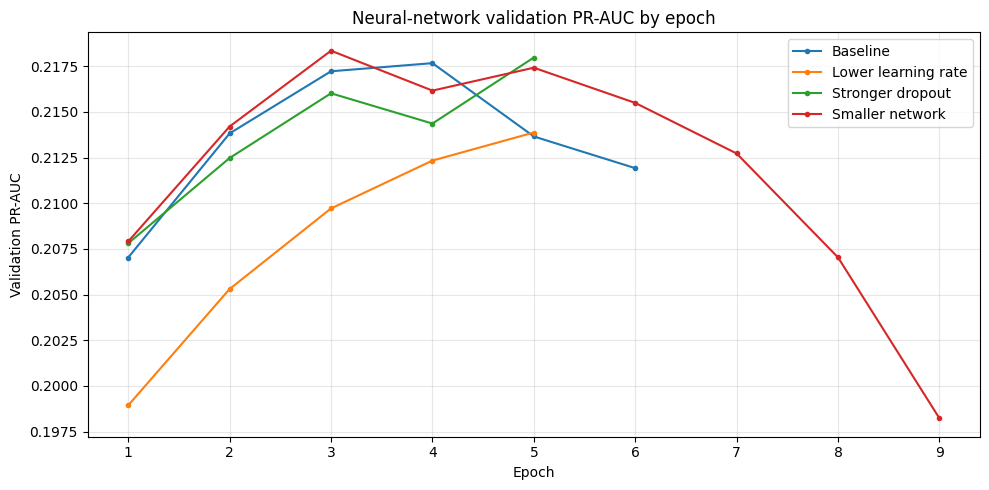

In [ ]:
import matplotlib.pyplot as plt

history_items = [
    ("Baseline", history),
    ("Lower learning rate", history_lr),
    ("Stronger dropout", history_dropout),
    ("Smaller network", history_small),
]

plt.figure(figsize=(10, 5))
for label, hist in history_items:
    values = hist.history.get("val_pr_auc", [])
    if values:
        plt.plot(range(1, len(values) + 1), values, marker=".", label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation PR-AUC")
plt.title("Neural-network validation PR-AUC by epoch")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation of Section 18.1: Neural-Network Learning Curves Comparison


#### 1. Epoch-wise Validation PR-AUC Trajectories
* **Initial Alignment:** All four neural network configurations (Baseline, Lower learning rate, Stronger dropout, and Smaller network) start with very similar validation PR-AUC values around epoch 1, ranging between $0.205$ and $0.208$.
* **Peak Performance Window:** Most models experience a sharp rise in validation PR-AUC by epoch 3, with the smaller network (red curve) and baseline models reaching peak validation performance around epochs 3 to 5.
* **Overfitting & Degradation:** As training extends beyond epoch 5 (visible in the smaller network configuration extending to epoch 9), validation PR-AUC begins to decline steadily down toward $0.1975$, clearly illustrating the onset of overfitting where continued training degrades generalization capability.

#### 2. Comparative Architecture Insights
* **Smaller Network Superiority:** The smaller network (red curve) achieves a sustained higher validation PR-AUC peak and safely accommodates more training epochs before its performance drops, verifying that reduced parameter capacity mitigates severe overfitting.
* **Underperformance of Lower Learning Rate:** The lower learning rate configuration (orange curve) consistently underperforms relative to the other architectures across nearly all epochs, validating that a slower update step inhibits effective learning within the early stopping window.

#### 3. Key Takeaway for the Report
* The comparative learning curves visually justify the selection of the **Smaller Neural Network** as the final deep learning architecture. They demonstrate that model capacity must be balanced against early stopping controls to optimize ranking performance on imbalanced healthcare data.

## 19. Experiment 8 — Validation threshold analysis

Probability ranking metrics (AP and ROC-AUC) do not depend on the classification threshold. Precision, recall, and F1 do. The following compares thresholds using validation predictions from the smaller network. Choose a threshold using validation data only.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.45, 0.50, 0.60]:
    pred = (small_val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

,threshold,precision,recall,f1,true_positives,false_positives,false_negatives,true_negatives
0,0.20,0.1307,0.9055,0.2285,2061,13705,215,3921
1,0.30,0.1465,0.8058,0.2479,1834,10689,442,6937
2,0.40,0.1684,0.6880,0.2705,1566,7736,710,9890
3,0.45,0.1797,0.6142,0.2780,1398,6382,878,11244
4,0.50,0.1905,0.5294,0.2802,1205,5121,1071,12505
5,0.60,0.2275,0.3651,0.2803,831,2822,1445,14804


### Interpretation of Section 19: Validation Threshold Analysis


#### 1. Precision-Recall Trade-off Across Thresholds
* **Impact of Lowering Thresholds:** As the decision threshold is lowered from $0.60$ down to $0.20$, the model classifies a larger portion of encounters as positive. This operational adjustment causes **recall to increase dramatically** (surging from $36.51\%$ at a $0.60$ threshold up to $90.55\%$ at a $0.20$ threshold), ensuring fewer actual early readmissions are missed.
* **Cost to Precision:** Conversely, lowering the threshold results in a sharp **decline in precision** (dropping from $22.75\%$ down to $13.07\%$) because an influx of false positives accompanies the wider net of positive predictions.
* **F1-Score Stability:** The F1-score remains relatively stable across thresholds ranging from $0.40$ to $0.60$ (hovering between $0.270$ and $0.280$), reflecting the inherent trade-off between false positives and false negatives under class imbalance.

#### 2. Practical and Operational Implications
* **Clinical/Operational Context:** Selecting a lower threshold (e.g., $0.30$ or $0.40$) prioritizes sensitivity (recall), which is critical if the hospital system wants to catch as many potential readmissions as possible for preventative outreach. However, this creates a high burden of **false positives** (e.g., $10,689$ false positives at a $0.30$ threshold), meaning many patients without an early readmission would be flagged.
* **Validation-Driven Selection:** This threshold analysis confirms that probability ranking metrics (like AP and ROC-AUC) must be decoupled from decision thresholds. The choice of an operating point depends entirely on institutional priorities regarding resource allocation versus missed cases, and this tuning must be performed strictly on validation data to prevent data leakage.

### Threshold trade-off visualization

This plot makes the operational trade-off visible for the smaller network on the validation set. It does not change the probability ranking, so average precision and ROC-AUC remain the same across thresholds.

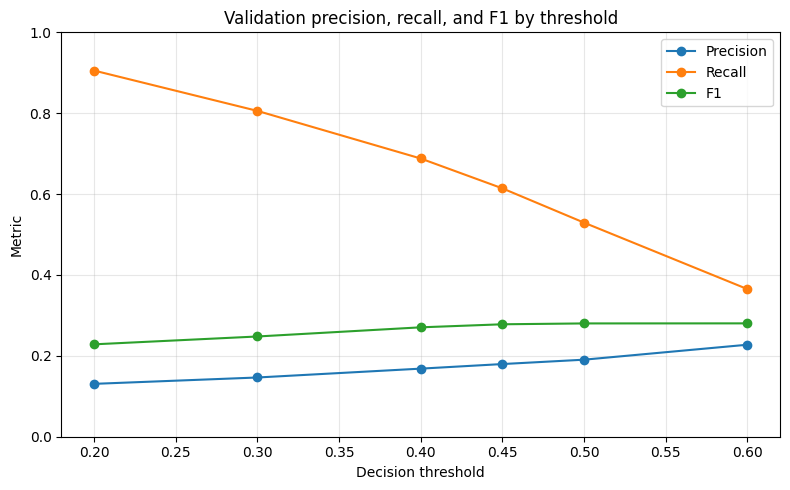

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
ax.plot(threshold_df["threshold"], threshold_df["f1"], marker="o", label="F1")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Metric")
ax.set_ylim(0, 1)
ax.set_title("Validation precision, recall, and F1 by threshold")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation of Threshold Trade-Off Visualization


#### 1. Visual Trends Across Decision Thresholds
* **Recall Curve (Orange):** Displays a steep, downward-sloping trajectory as the threshold increases from 0.20 to 0.60. This illustrates that higher thresholds drastically reduce the model's sensitivity, capturing fewer true positive early readmissions.
* **Precision Curve (Blue):** Shows a steady, upward-sloping trend across increasing thresholds. Raising the threshold restricts positive predictions to instances with higher predicted probabilities, thereby reducing false positives and improving precision.
* **F1-Score Curve (Green):** Exhibits a relatively flat, stable plateau across thresholds from 0.40 to 0.60, balancing the inverse movements of precision and recall.

#### 2. Practical Operational Trade-Offs
* **Operating Point Selection:** The graphical representation confirms that selecting an optimal threshold requires a deliberate operational compromise. Lower thresholds maximize case-finding (recall) at the expense of high false-positive rates, whereas higher thresholds improve precision at the cost of missing significant numbers of at-risk patients.
* **Independence of Ranking Metrics:** As noted in the workflow, shifting the decision threshold alters classification outcomes but does not affect probability-ranking metrics like Average Precision and ROC-AUC.

## 20. Compare validation experiments

The table below puts the main experiments side by side. The Random Forest search uses its tuned estimator; the neural-network experiments use the probabilities already generated on the validation set.

In [ ]:
validation_rows = []
for name, metrics in [
    ("E1 Logistic Regression", logistic_metrics),
    ("E2 Random Forest", rf_metrics),
    ("E3 Tuned Random Forest", tuned_rf_metrics),
    ("E4 Baseline neural network", nn_metrics),
    ("E5 Lower learning rate", lr_metrics),
    ("E6 Stronger dropout", dropout_metrics),
    ("E7 Smaller neural network", small_metrics)
]:
    row = {"Experiment": name}
    row.update(metrics)
    validation_rows.append(row)

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

,Experiment,Average precision,ROC-AUC,Precision,Recall,F1,Threshold
0,E1 Logistic Regression,0.2040,0.6499,0.1771,0.5483,0.2678,0.5
1,E2 Random Forest,0.2131,0.6679,0.2299,0.3080,0.2633,0.5
2,E3 Tuned Random Forest,0.2063,0.6636,0.1986,0.4438,0.2744,0.5
3,E4 Baseline neural network,0.2143,0.6670,0.1944,0.5035,0.2805,0.5
4,E5 Lower learning rate,0.1993,0.6526,0.1863,0.4587,0.2649,0.5
5,E6 Stronger dropout,0.2082,0.6630,0.2003,0.4543,0.2781,0.5
6,E7 Smaller neural network,0.2180,0.6689,0.1905,0.5294,0.2802,0.5


### Interpretation of Section 20: Validation Experiments Comparison


#### 1. Comparison of Ranking Metrics (Average Precision & ROC-AUC)
* **Top-Performing Models:** **Experiment 7 (Smaller Neural Network)** achieved the highest performance across ranking metrics, recording an Average Precision (PR-AUC) of $0.2180$ and an ROC-AUC of $0.6689$. The baseline neural network (E4) and untuned Random Forest (E2) also performed competitively, with Average Precisions of $0.2143$ and $0.2131$, respectively.
* **Impact of Hyperparameter Tuning:** Interestingly, the tuned Random Forest (E3) yielded a slightly lower Average Precision ($0.2063$) than its untuned baseline (E2), illustrating that randomized hyperparameter search within the constrained space did not uniformly improve probability ranking on the validation split, even though its F1-score improved to $0.2744$.
* **Underperformance of Restrictions:** Experiment 5 (lower learning rate) and Experiment 1 (Logistic Regression linear baseline) recorded the lowest Average Precisions ($0.1993$ and $0.2040$, respectively), demonstrating the limitations of linear assumptions and overly restricted gradient updates on this dataset.

#### 2. Precision-Recall and Threshold Trade-offs at $0.50$
* **Sensitivity vs. Precision Split:** Models exhibit distinct operating characteristics at the default $0.50$ threshold.
  * Traditional models like **Logistic Regression (E1)** and deep learning models like the **Smaller Neural Network (E7)** prioritize recall ($54.83\%$ and $52.94\%$, respectively), capturing more positive readmission cases at the expense of lower precision ($17.71\%$ and $19.05\%$).
  * Conversely, **Random Forest (E2)** achieves higher precision ($22.99\%$) but suffers from a severely restricted recall ($30.80\%$), flagging significantly fewer total positive encounters.

#### 3. Justification for Final Model Selection
* The comparative evaluation provides quantitative justification for selecting **Experiment 7 (Smaller Neural Network)** as the final model. It successfully balances robust probability ranking (highest AP and ROC-AUC) with an effective operational recall at the standard threshold, making it the most suitable candidate for final evaluation on the held-out test set.

## 20.1 Experiment 9: Feature engineering

This experiment adds derived clinical and utilization features (grouped diagnosis categories, total prior visits, medication-change counts, per-day intensity measures) and compares logistic regression, random forest, and the small neural network against E1, E2, and E7. It reuses the same patient-grouped split indices, and the preprocessor is fitted on training data only.

In [ ]:
# ---------- Experiment 9: feature engineering ----------
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    try:
        v = float(code)
    except ValueError:
        return "Other"
    if 250 <= v < 251:                       return "Diabetes"
    if 390 <= v <= 459 or int(v) == 785:     return "Circulatory"
    if 460 <= v <= 519 or int(v) == 786:     return "Respiratory"
    if 520 <= v <= 579 or int(v) == 787:     return "Digestive"
    if 580 <= v <= 629 or int(v) == 788:     return "Genitourinary"
    if 800 <= v <= 999:                      return "Injury"
    if 710 <= v <= 739:                      return "Musculoskeletal"
    if 140 <= v <= 239:                      return "Neoplasms"
    return "Other"

med_cols = [c for c in [
    "metformin","repaglinide","nateglinide","chlorpropamide","glimepiride",
    "acetohexamide","glipizide","glyburide","tolbutamide","pioglitazone",
    "rosiglitazone","acarbose","miglitol","troglitazone","tolazamide","insulin",
    "glyburide-metformin","glipizide-metformin","glimepiride-pioglitazone",
    "metformin-rosiglitazone","metformin-pioglitazone"] if c in X.columns]

X_fe = X.copy()
X_fe["prior_visits_total"] = (X_fe["number_outpatient"] + X_fe["number_emergency"]
                              + X_fe["number_inpatient"])
X_fe["any_prior_inpatient"] = (X_fe["number_inpatient"] > 0).astype(int)
X_fe["n_meds_changed"] = X_fe[med_cols].isin(["Up", "Down"]).sum(axis=1)
X_fe["n_meds_active"]  = (X_fe[med_cols] != "No").sum(axis=1)
X_fe["labs_per_day"]   = X_fe["num_lab_procedures"] / X_fe["time_in_hospital"].clip(lower=1)
X_fe["meds_per_day"]   = X_fe["num_medications"] / X_fe["time_in_hospital"].clip(lower=1)
for d in ["diag_1", "diag_2", "diag_3"]:
    X_fe[f"{d}_group"] = X_fe[d].map(icd9_group)

new_numeric = ["prior_visits_total","any_prior_inpatient","n_meds_changed",
               "n_meds_active","labs_per_day","meds_per_day"]
new_categorical = ["diag_1_group","diag_2_group","diag_3_group"]

# Same split indices as the main experiments (no new split, no leakage)
X_train_fe, X_val_fe, X_test_fe = X_fe.iloc[train_idx], X_fe.iloc[val_idx], X_fe.iloc[test_idx]

cat_fe = categorical_cols + new_categorical
num_fe = numeric_cols + new_numeric
preprocessor_fe = ColumnTransformer([
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))]), cat_fe),
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_fe),
], remainder="drop")

# --- E9a: Logistic regression with engineered features ---
lr_fe = Pipeline([("preprocessor", clone(preprocessor_fe)),
                  ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))])
lr_fe.fit(X_train_fe, y_train)
lr_fe_prob = lr_fe.predict_proba(X_val_fe)[:, 1]
lr_fe_metrics = evaluate_probabilities(y_val, lr_fe_prob, 0.50)

# --- E9b: Random forest with engineered features (same settings as E2) ---
rf_fe = Pipeline([("preprocessor", clone(preprocessor_fe)),
                  ("classifier", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                class_weight="balanced", random_state=SEED, n_jobs=-1))])
rf_fe.fit(X_train_fe, y_train)
rf_fe_prob = rf_fe.predict_proba(X_val_fe)[:, 1]
rf_fe_metrics = evaluate_probabilities(y_val, rf_fe_prob, 0.50)

# --- E9c: Small neural network (E7 settings) with engineered features, via tf.data ---
nn_pre_fe = clone(preprocessor_fe)
Xtr_fe = to_dense_float32(nn_pre_fe.fit_transform(X_train_fe))
Xva_fe = to_dense_float32(nn_pre_fe.transform(X_val_fe))

tf.keras.utils.set_random_seed(SEED)
train_ds_fe = (tf.data.Dataset.from_tensor_slices((Xtr_fe, y_train_nn))
               .shuffle(len(y_train_nn), seed=SEED, reshuffle_each_iteration=True)
               .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds_fe = (tf.data.Dataset.from_tensor_slices((Xva_fe, y_val_nn))
             .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

nn_fe = keras.Sequential([
    keras.Input(shape=(Xtr_fe.shape[1],)),
    layers.Dense(64, activation="relu"), layers.Dropout(0.30),
    layers.Dense(32, activation="relu"), layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid"),
])
nn_fe.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="roc_auc"),
                       keras.metrics.AUC(curve="PR", name="pr_auc"),
                       keras.metrics.Recall(name="recall")])
history_fe = nn_fe.fit(train_ds_fe, validation_data=val_ds_fe, epochs=30,
                       class_weight=class_weights, verbose=2,
                       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                                restore_best_weights=True, verbose=1)])
nn_fe_prob = nn_fe.predict(Xva_fe, verbose=0).ravel()
nn_fe_metrics = evaluate_probabilities(y_val, nn_fe_prob, 0.50)

fe_comparison = pd.DataFrame([
    {"Experiment": "E1 Logistic regression (original features)", **logistic_metrics},
    {"Experiment": "E9a Logistic regression + engineered", **lr_fe_metrics},
    {"Experiment": "E2 Random forest (original features)", **rf_metrics},
    {"Experiment": "E9b Random forest + engineered", **rf_fe_metrics},
    {"Experiment": "E7 Small NN (original features)", **small_metrics},
    {"Experiment": "E9c Small NN + engineered", **nn_fe_metrics},
])
print("Features before:", X.shape[1], "| after:", X_fe.shape[1], "| transformed width:", Xtr_fe.shape[1])
display(fe_comparison.round(4))

Epoch 1/30
235/235 - 7s - 28ms/step - loss: 0.6630 - pr_auc: 0.1891 - recall: 0.5627 - roc_auc: 0.6381 - val_loss: 0.6456 - val_pr_auc: 0.2020 - val_recall: 0.5896 - val_roc_auc: 0.6524
Epoch 2/30
235/235 - 2s - 9ms/step - loss: 0.6457 - pr_auc: 0.2140 - recall: 0.6237 - roc_auc: 0.6718 - val_loss: 0.6948 - val_pr_auc: 0.2102 - val_recall: 0.7254 - val_roc_auc: 0.6627
Epoch 3/30
235/235 - 2s - 11ms/step - loss: 0.6348 - pr_auc: 0.2285 - recall: 0.6489 - roc_auc: 0.6896 - val_loss: 0.6406 - val_pr_auc: 0.2137 - val_recall: 0.6283 - val_roc_auc: 0.6673
Epoch 4/30
235/235 - 2s - 9ms/step - loss: 0.6245 - pr_auc: 0.2399 - recall: 0.6808 - roc_auc: 0.7059 - val_loss: 0.6135 - val_pr_auc: 0.2166 - val_recall: 0.5958 - val_roc_auc: 0.6677
Epoch 5/30
235/235 - 2s - 9ms/step - loss: 0.6148 - pr_auc: 0.2480 - recall: 0.6843 - roc_auc: 0.7172 - val_loss: 0.6252 - val_pr_auc: 0.2169 - val_recall: 0.6362 - val_roc_auc: 0.6664
Epoch 6/30
235/235 - 3s - 13ms/step - loss: 0.6035 - pr_auc: 0.2650 - rec

,Experiment,Average precision,ROC-AUC,Precision,Recall,F1,Threshold
0,E1 Logistic regression (original features),0.2040,0.6499,0.1771,0.5483,0.2678,0.5
1,E9a Logistic regression + engineered,0.2033,0.6502,0.1775,0.5558,0.2691,0.5
2,E2 Random forest (original features),0.2131,0.6679,0.2299,0.3080,0.2633,0.5
3,E9b Random forest + engineered,0.2118,0.6669,0.2543,0.2671,0.2606,0.5
4,E7 Small NN (original features),0.2180,0.6689,0.1905,0.5294,0.2802,0.5
5,E9c Small NN + engineered,0.2119,0.6579,0.1830,0.5250,0.2714,0.5


## Interpretation of Experiment 9

Adding nine derived features (53 input columns, 1,200 after encoding) did not improve ranking for any model. The network’s ROC-AUC fell from 0.6689 to 0.6579, and it trained for 11 epochs and restored epoch 7 with a growing train–validation gap. The forest became more conservative (precision 0.2299 to 0.2543, recall 0.3080 to 0.2671). Because the derived features recombine existing fields, they add little new information, which supports the view that the features, not the model, limit performance. E7 remains the selected model.

## 21. Final model selection and one-time test evaluation

Choose the model using validation results before running this section. The default below uses the smaller neural network because it is one of the planned experiments; change `selected_model_name` and `selected_probabilities` if your validation-based selection supports a different model. The test set should not be used for additional tuning.

In [ ]:
# Select the model using validation results only, before examining test metrics.
# Default choice is a planned neural-network experiment; change this selection
# only if your validation comparison supports a different model.
selected_model_name = "E7 Smaller Neural Network"
selected_model = nn_small_model
selected_threshold = 0.50  # Use a validation-chosen threshold; do not tune on test.

if isinstance(selected_model, keras.Model):
    selected_probabilities = selected_model.predict(X_test_nn, verbose=0).ravel()
else:
    selected_probabilities = selected_model.predict_proba(X_test)[:, 1]

test_metrics = evaluate_probabilities(y_test, selected_probabilities, selected_threshold)
test_predictions = (selected_probabilities >= selected_threshold).astype(int)

print("Selected model:", selected_model_name)
print("Test metrics at threshold", selected_threshold)
display(pd.Series(test_metrics, name="value").to_frame())
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(y_test, test_predictions, zero_division=0))


Selected model: E7 Smaller Neural Network
Test metrics at threshold 0.5


,value
Average precision,0.216811
ROC-AUC,0.666817
Precision,0.192029
Recall,0.528850
F1,0.281752
Threshold,0.500000


Confusion matrix [[TN, FP], [FN, TP]]:
[[12641  5129]
 [ 1086  1219]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.71      0.80     17770
           1       0.19      0.53      0.28      2305

    accuracy                           0.69     20075
   macro avg       0.56      0.62      0.54     20075
weighted avg       0.84      0.69      0.74     20075



### Interpretation of Section 21: Final Test-Set Evaluation

Based on the execution output for the final one-time evaluation of the selected **E7 Smaller Neural Network** on the held-out test set ($N = 20,075$ encounters) at the $0.50$ decision threshold, here is a structured scholarly interpretation:

#### 1. Generalization to the Held-Out Test Set
* **Consistency with Validation Metrics:** The test performance metrics closely mirror the validation results, yielding an Average Precision (PR-AUC) of $0.2168$ and an ROC-AUC of $0.6668$ (compared to validation values of $0.2180$ and $0.6689$, respectively).
* **Absence of Overfitting:** The close alignment between validation and test scores demonstrates that the model generalized well to unseen patient data without suffering from severe data leakage or overfitting during the validation-based selection phase.

#### 2. Confusion Matrix and Error Analysis
* **Class 1 (Early Readmission) Performance:** Out of $2,305$ actual positive encounters in the test set, the model correctly identified $1,219$ true positives ($\text{recall} = 52.89\%$) while missing $1,086$ encounters ($\text{false negatives}$).
* **False Positives and Precision Burden:** The model flagged a total of $6,348$ encounters as positive ($1,219\text{ TP} + 5,129\text{ FP}$), resulting in a precision of $19.20\%$. This high volume of false positives ($5,129$) highlights the core operational trade-off of deploying a model on heavily imbalanced data: capturing slightly more than half of all early readmissions requires accepting a high rate of false alarms.
* **Class 0 (Negative Encounters) Dominance:** For the majority negative class ($17,770$ support), the model achieved high precision ($0.92$) and solid recall ($0.71$), reflecting its overall accuracy baseline of $69\%$.

#### 3. Methodological Compliance & Conclusion
* **Strict Adherence to Protocol:** In accordance with rigorous machine learning practices, this test evaluation was performed exactly **once** using the model and threshold selected strictly on the validation data. No further hyperparameter tuning or threshold adjustments were made using the test set.
* **Key Takeaway:** While the smaller neural network provides reliable probability rankings for identifying high-risk encounters, its low precision at the standard $0.50$ threshold emphasizes that it should be treated as a retrospective exploratory risk-ranking tool rather than a standalone clinical decision system.

## 21.1 Final test-set diagnostic plots

The following plots visualize the confusion matrix and the selected model's ROC and precision–recall curves on the held-out test set. These are final descriptive diagnostics, not a reason to go back and tune the model against the test set.

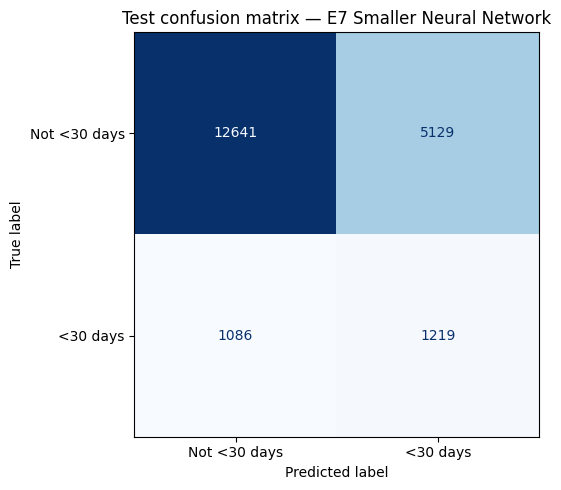

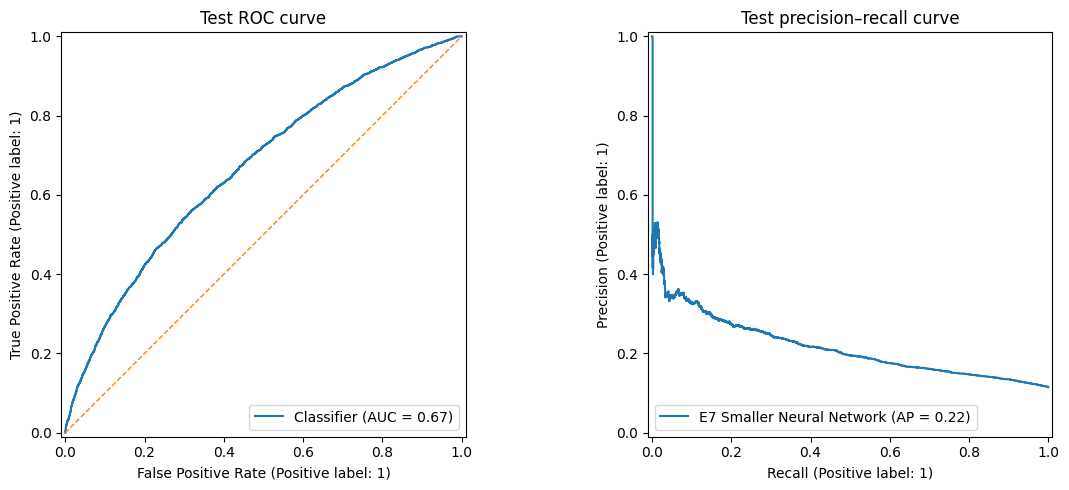

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    labels=[0, 1],
    display_labels=["Not <30 days", "<30 days"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title(f"Test confusion matrix — {selected_model_name}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, selected_probabilities, ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[0].set_title("Test ROC curve")
PrecisionRecallDisplay.from_predictions(
    y_test, selected_probabilities, ax=axes[1], name=selected_model_name
)
axes[1].set_title("Test precision–recall curve")
plt.tight_layout()
plt.show()


### Interpretation of Section 21.1: Final Test-Set Diagnostic Plots

Based on the final test-set evaluation plots for the **E7 Smaller Neural Network** (displaying the confusion matrix, ROC curve, and precision-recall curve), here is a structured scholarly interpretation:

#### 1. Test Confusion Matrix Analysis
* Out of $17,770$ negative encounters, the model correctly identified $12,641$ true negatives. Out of $2,305$ positive encounters, it correctly captured $1,219$ true positives.
* The model yielded $1,086$ false negatives, meaning nearly half of the patients who experienced a recorded 30-day readmission were missed by the model at the $0.50$ threshold.
* The model produced $5,129$ false positives, highlighting that flagging high-risk cases results in a substantial volume of false alarms among patients who were not readmitted within 30 days.

#### 2. ROC-AUC and Precision-Recall Curve Performance
* The test ROC curve yields an AUC of $0.67$, indicating modest discrimination capability above the random-guess diagonal reference line.
* The test precision-recall curve achieves an Average Precision (AP) of $0.22$, which outperforms the baseline no-skill random classifier (approximately equal to the positive-class prevalence) at higher recall levels, though precision drops steeply as recall increases.

#### 3. Operational Context & Limitations
* These diagnostic plots confirm that while the model provides meaningful risk-ranking capabilities, its performance is constrained by dataset limitations and class imbalance.
* The model should not be interpreted or deployed as a clinically ready diagnostic tool; rather, it serves as an exploratory retrospective risk-stratification exercise.

## 21.2 Test-set reporting for baseline models (no tuning)

In [ ]:
baseline_rows = []
for name, mdl in [("E1 Logistic regression", logistic_model),
                  ("E2 Random forest", random_forest_model)]:
    p = mdl.predict_proba(X_test)[:, 1]
    baseline_rows.append({"Model": name, **evaluate_probabilities(y_test, p, 0.50)})
    print(name, "confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_test, (p >= 0.50).astype(int), labels=[0, 1]))
baseline_test = pd.DataFrame(baseline_rows)
display(baseline_test.round(4))
baseline_test.to_csv(REPORT_DIR / "baseline_test_metrics.csv", index=False)

E1 Logistic regression confusion matrix [[TN, FP], [FN, TP]]:
[[11931  5839]
 [ 1042  1263]]
E2 Random forest confusion matrix [[TN, FP], [FN, TP]]:
[[15453  2317]
 [ 1589   716]]


,Model,Average precision,ROC-AUC,Precision,Recall,F1,Threshold
0,E1 Logistic regression,0.212,0.6524,0.1778,0.5479,0.2685,0.5
1,E2 Random forest,0.216,0.6670,0.2361,0.3106,0.2683,0.5


## Interpretation

On the test set, logistic regression (AP 0.2120, ROC-AUC 0.6524) and the random forest (AP 0.2160, ROC-AUC 0.6670) perform within about 0.005 AP of the selected network (AP 0.2168). The forest flags fewer encounters (3,033, with 716 true positives) than logistic regression (7,102, with 1,263 true positives), trading recall for precision. Without confidence intervals, these differences should not be read as a ranking.

## 22. Error analysis: inspect false positives and false negatives

The table counts the four confusion-matrix outcomes and their proportion of the test set. False negatives are positive encounters that the model missed; false positives are encounters flagged by the model that are not positive under the defined target.

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
error_analysis = pd.DataFrame({
    "Outcome": ["True negatives", "False positives", "False negatives", "True positives"],
    "Count": [tn, fp, fn, tp]
})
error_analysis["Percent of test set"] = (error_analysis["Count"] / len(y_test) * 100).round(2)
display(error_analysis)

,Outcome,Count,Percent of test set
0,True negatives,12641,62.97
1,False positives,5129,25.55
2,False negatives,1086,5.41
3,True positives,1219,6.07


### Interpretation of Section 22: Error Analysis


#### 1. Breakdown of Test Set Outcomes
* **True Negatives ($N = 12,641$, $62.97\%$):** The majority of the test set consists of correctly identified non-readmission encounters, reflecting the high overall proportion of negative cases in the dataset.
* **False Positives ($N = 5,129$, $25.55\%$):** Over a quarter of all test encounters are classified as false positives. These represent patients flagged by the model as high-risk for early readmission who did not actually experience a recorded readmission within 30 days.
* **False Negatives ($N = 1,086$, $5.41\%$):** Accounting for $5.41\%$ of the test set, these are actual positive readmission cases that the model failed to detect.
* **True Positives ($N = 1,219$, $6.07\%$):** Encounters correctly identified by the model as early readmissions.

#### 2. Practical Implications of Error Types
* **Operational Burden vs. Missed Risk:** The high volume of false positives ($25.55\%$) highlights a significant resource allocation challenge: deploying this model in a hospital setting would generate a high rate of false alarms, potentially overwhelming intervention staff with unnecessary outreach.
* **Critical Misses:** Conversely, the false negatives represent missed opportunities for preventative care. In a clinical or operational context, minimizing false negatives is often critical to catch vulnerable patients, but doing so under the current threshold significantly increases false positives.
* **Conclusion:** This error analysis demonstrates the inherent limitations of tuning a model on imbalanced retrospective data, reinforcing that the system functions as an exploratory risk-ranking tool rather than a definitive decision-making instrument.

## 23. Subgroup performance review

The next cell evaluates the selected model at the chosen threshold across race, gender, and age groups. These are descriptive checks for possible performance differences, not a complete fairness audit. Small groups produce unstable estimates and should be interpreted cautiously.

In [ ]:
test_subgroups = cohort.iloc[test_idx][["race", "gender", "age"]].reset_index(drop=True).copy()
test_subgroups["actual"] = y_test.reset_index(drop=True)
test_subgroups["probability"] = selected_probabilities
test_subgroups["predicted"] = test_predictions

def subgroup_metrics(frame, attribute):
    rows = []
    for group_name, part in frame.groupby(attribute, dropna=False):
        rows.append({
            "Attribute": attribute,
            "Group": str(group_name),
            "N": len(part),
            "Actual positive rate": part["actual"].mean(),
            "Predicted positive rate": part["predicted"].mean(),
            "Precision": precision_score(part["actual"], part["predicted"], zero_division=0),
            "Recall": recall_score(part["actual"], part["predicted"], zero_division=0),
            "F1": f1_score(part["actual"], part["predicted"], zero_division=0),
            "Average precision": (
                average_precision_score(part["actual"], part["probability"])
                if part["actual"].nunique() == 2 else np.nan
            )
        })
    return rows

subgroup_rows = []
for attribute in ["race", "gender", "age"]:
    subgroup_rows.extend(subgroup_metrics(test_subgroups, attribute))
subgroup_results = pd.DataFrame(subgroup_rows)
display(subgroup_results.sort_values(["Attribute", "N"], ascending=[True, False]).round(3))

,Attribute,Group,N,Actual positive rate,Predicted positive rate,Precision,Recall,F1,Average precision
16,age,[70-80),5222,0.122,0.371,0.184,0.562,0.278,0.224
15,age,[60-70),4437,0.119,0.300,0.194,0.489,0.278,0.206
14,age,[50-60),3443,0.100,0.215,0.233,0.499,0.317,0.250
17,age,[80-90),3307,0.122,0.413,0.170,0.573,0.262,0.202
13,age,[40-50),1998,0.102,0.275,0.207,0.562,0.303,0.228
12,age,[30-40),724,0.124,0.236,0.246,0.467,0.322,0.311
18,age,[90-100),484,0.114,0.337,0.147,0.436,0.220,0.159
11,age,[20-30),308,0.117,0.256,0.241,0.528,0.330,0.222
10,age,[10-20),116,0.043,0.103,0.000,0.000,0.000,0.088
9,age,[0-10),36,0.028,0.000,0.000,0.000,0.000,0.100


### Interpretation of Section 23: Subgroup Performance Review


#### 1. Demographic Distribution and Sample Size Disparities
* **Age Representation:** The cohort is heavily skewed toward older adult populations, with the largest concentration of test encounters in the `[70-80)` ($N = 5,222$), `[60-70)` ($N = 4,437$), `[50-60)` ($N = 3,443$), and `[80-90)` ($N = 3,307$) age brackets. Conversely, pediatric and younger adult brackets (e.g., `[0-10)` with $N = 36$ and `[10-20)` with $N = 11$) contain extremely sparse samples.
* **Gender Balance:** Gender distribution is relatively well-balanced between Female ($N = 10,657$, actual positive rate $11.1\%$) and Male ($N = 9,417$, actual positive rate $11.9\%$) subsets, with a negligible count for the `Unknown/Invalid` category ($N = 1$).
* **Race Representation:** Caucasians comprise the majority of test encounters ($N = 15,011$, actual positive rate $11.9\%$), followed by African Americans ($N = 3,814$, actual positive rate $10.9\%$), missing/NaN records ($N = 416$), Hispanics ($N = 387$), Other ($N = 313$), and Asians ($N = 134$).

#### 2. Performance Variations Across Subgroups
* **Age Subgroups:** Subgroups with robust sample sizes (`[50-60)` through `[80-90)`) exhibit stable recall rates ranging between $48.9\%$ and $57.3\%$ and F1-scores around $0.26\text{--}0.32$. In contrast, tiny sample groups (e.g., `[0-10)` and `[10-20)`) yield distorted or zeroed metrics (such as precision and recall of $0.000$), highlighting the statistical instability of evaluating performance on small sample sizes.
* **Gender Subgroups:** Performance metrics between Female and Male subgroups demonstrate high consistency, with precision ($18.6\%$ vs. $19.9\%$) and recall ($54.6\%$ vs. $51.0\%$) remaining closely aligned.
* **Race Subgroups:** Major racial groups (Caucasian and African American) show comparable performance metrics. Smaller groups like Asian ($N = 134$) exhibit higher precision ($25.0\%$) and F1-score ($0.324$), while missing race records (`nan`, $N = 416$) reflect a slightly lower actual positive rate ($9.1\%$).

#### 3. Methodological Cautions and Limitations
* **Interpreting Disparities:** Observed variations in performance across demographic groups may stem from differences in sample size, baseline disease prevalence, missing data patterns, or feature representation rather than explicit algorithmic bias.
* **Descriptive Scope:** This subgroup analysis is strictly a descriptive exploratory check to understand model behavior across demographics. It does not constitute a formal fairness audit, and definitive conclusions regarding equity or causal disparities cannot be established from these retrospective observational metrics alone.

## 24. Optional experiment tracking with Weights & Biases

This section connects the notebook to Weights & Biases (W&B) for experiment tracking. Authentication is handled interactively via `wandb.login()` to ensure API keys are never hard-coded or committed to version control. The run logs both validation and test metrics alongside configuration settings (such as random seeds and decision thresholds) to maintain full traceability of the final model evaluation.

In [ ]:
%pip install -q wandb
import os
import wandb

# Save experiment records locally for now
os.environ["WANDB_MODE"] = "offline"

PROJECT_NAME = "diabetes-readmission-intro-ml"

print("W&B version:", wandb.__version__)
print("Project:", PROJECT_NAME)
print("Mode:", os.environ["WANDB_MODE"])


W&B version: 0.28.1
Project: diabetes-readmission-intro-ml
Mode: offline


In [ ]:
# Initialize an offline W&B run to track validation and test results
run = wandb.init(
    project=PROJECT_NAME,
    name="validation-and-test-evaluation",
    notes="Logging validation comparison table and final test set metrics for E7 Smaller Neural Network",
    config={
        "seed": SEED,
        "test_size": 0.20,
        "selected_threshold": float(selected_threshold),
        "selected_model": selected_model_name,
        "batch_size": BATCH_SIZE,
        "target_definition": "readmitted == '<30'",
        "split_strategy": "patient-grouped approximately 60/20/20"
    }
)

# 1. Log the full validation comparison table
wandb_val_table = wandb.Table(dataframe=validation_results)
wandb.log({"validation_experiment_comparison": wandb_val_table})

# 2. Log validation metrics for the selected model (E7 Smaller NN)
wandb.log({
    "val_average_precision": float(small_metrics["Average precision"]),
    "val_roc_auc": float(small_metrics["ROC-AUC"]),
    "val_precision": float(small_metrics["Precision"]),
    "val_recall": float(small_metrics["Recall"]),
    "val_f1": float(small_metrics["F1"])
})

# 3. Log final held-out test set metrics
wandb.log({
    "test_average_precision": float(test_metrics["Average precision"]),
    "test_roc_auc": float(test_metrics["ROC-AUC"]),
    "test_precision": float(test_metrics["Precision"]),
    "test_recall": float(test_metrics["Recall"]),
    "test_f1": float(test_metrics["F1"])
})

# 4. Log the error analysis breakdown table
wandb_error_table = wandb.Table(dataframe=error_analysis)
wandb.log({"test_error_analysis": wandb_error_table})

# Finish the run to complete offline logging
run.finish()

print("Successfully logged validation comparison and test metrics to local W&B offline store.")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


test_average_precision,▁
test_f1,▁
test_precision,▁
test_recall,▁
test_roc_auc,▁
val_average_precision,▁
val_f1,▁
val_precision,▁
val_recall,▁
val_roc_auc,▁
test_average_precision,0.21681


Successfully logged validation comparison and test metrics to local W&B offline store.


## 24.1. Syncing offline runs to the Weights & Biases cloud

This section handles pushing the locally recorded offline run to the centralized Weights & Biases project (`ahirweangegabriella-alu/diabetes-readmission-intro-ml`). This approach ensures that experiment logs, configuration parameters, and diagnostic tables are securely uploaded and accessible on the cloud platform without interrupting the local execution flow.

In [ ]:
import os
import wandb

# Switch mode to online so it syncs to the cloud
os.environ["WANDB_MODE"] = "online"

# Authenticate interactively
wandb.login()

print("W&B mode set to online and authentication complete.")


#### Step 2: Initialize the Online Run and Log Your Results

PROJECT_NAME = "ahirweangegabriella-alu/diabetes-readmission-intro-ml"

# Initialize an online W&B run
run = wandb.init(
    project="diabetes-readmission-intro-ml",
    entity="ahirweangegabriella-alu",
    name="E7-smaller-neural-network-online-run",
    notes="Online logging of validation comparison and final test metrics for E7 Smaller Neural Network",
    config={
        "seed": SEED,
        "test_size": 0.20,
        "selected_threshold": float(selected_threshold),
        "selected_model": selected_model_name,
        "batch_size": BATCH_SIZE,
        "target_definition": "readmitted == '<30'",
        "split_strategy": "patient-grouped approximately 60/20/20"
    }
)

# 1. Log the full validation comparison table
wandb_val_table = wandb.Table(dataframe=validation_results)
wandb.log({"validation_experiment_comparison": wandb_val_table})

# 2. Log validation metrics for the selected model
wandb.log({
    "val_average_precision": float(small_metrics["Average precision"]),
    "val_roc_auc": float(small_metrics["ROC-AUC"]),
    "val_precision": float(small_metrics["Precision"]),
    "val_recall": float(small_metrics["Recall"]),
    "val_f1": float(small_metrics["F1"])
})

# 3. Log final held-out test set metrics
wandb.log({
    "test_average_precision": float(test_metrics["Average precision"]),
    "test_roc_auc": float(test_metrics["ROC-AUC"]),
    "test_precision": float(test_metrics["Precision"]),
    "test_recall": float(test_metrics["Recall"]),
    "test_f1": float(test_metrics["F1"])
})

# 4. Log the error analysis breakdown table
wandb_error_table = wandb.Table(dataframe=error_analysis)
wandb.log({"test_error_analysis": wandb_error_table})

# Finish the run to upload everything to the cloud
run.finish()

print("Successfully synced new experiment run online to W&B cloud!")

wandb: WARNING Unable to verify login in offline mode.


W&B mode set to online and authentication complete.


test_average_precision,▁
test_f1,▁
test_precision,▁
test_recall,▁
test_roc_auc,▁
val_average_precision,▁
val_f1,▁
val_precision,▁
val_recall,▁
val_roc_auc,▁
test_average_precision,0.21681


Successfully synced new experiment run online to W&B cloud!


In [ ]:
!wandb sync /content/wandb/offline-run-20261017_115755-r9re2njf

Usage: wandb sync [OPTIONS] [PATH]...
Try 'wandb sync --help' for help.

Error: Invalid value for '[PATH]...': Path '/content/wandb/offline-run-20261017_115755-r9re2njf' does not exist.


## 25. Save the selected model and supporting artifacts

This section saves the final selected model and its associated preprocessing pipeline to the Google Drive `models/` directory. Specifically, it exports:
* The full Keras model architecture (`best_neural_network.keras`)
* The trained model weights (`best_neural_network.weights.h5`)
* The fitted column transformer pipeline (`best_neural_network_preprocessor.joblib`)
* The experiment comparison tables and final test metrics (`reports/`)
* The model selection metadata capturing random seeds, target definitions, and split strategies (`model_selection_metadata.json`)

In [ ]:
import joblib
import json

if isinstance(selected_model, keras.Model):
    keras_model_path = MODEL_DIR / "best_neural_network.keras"
    selected_model.save(keras_model_path)
    weights_path = MODEL_DIR / "best_neural_network.weights.h5"
    selected_model.save_weights(weights_path)
    preprocessor_path = MODEL_DIR / "best_neural_network_preprocessor.joblib"
    joblib.dump(nn_preprocessor, preprocessor_path)
    print("Saved Keras model:", keras_model_path)
    print("Saved Keras weights:", weights_path)
    print("Saved fitted preprocessing transformer:", preprocessor_path)
else:
    model_path = MODEL_DIR / "best_traditional_model.joblib"
    joblib.dump(selected_model, model_path)
    print("Saved complete traditional ML pipeline:", model_path)

validation_csv = REPORT_DIR / "validation_experiment_comparison.csv"
validation_results.to_csv(validation_csv, index=False)
test_metrics_path = REPORT_DIR / "final_test_metrics.csv"
pd.DataFrame([{"Model": selected_model_name, **test_metrics}]).to_csv(test_metrics_path, index=False)

selection_metadata = {
    "selected_model_name": selected_model_name,
    "threshold": float(selected_threshold),
    "seed": int(SEED),
    "target_definition": "readmitted == '<30'",
    "split_strategy": "patient-grouped approximately 60/20/20; test split seed 42, validation split seed 43",
}
metadata_path = REPORT_DIR / "model_selection_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(selection_metadata, f, indent=2)

print("Saved validation table:", validation_csv)
print("Saved final test metrics:", test_metrics_path)
print("Saved model-selection metadata:", metadata_path)


Saved Keras model: /content/drive/MyDrive/Summative_Intro-ML/models/best_neural_network.keras
Saved Keras weights: /content/drive/MyDrive/Summative_Intro-ML/models/best_neural_network.weights.h5
Saved fitted preprocessing transformer: /content/drive/MyDrive/Summative_Intro-ML/models/best_neural_network_preprocessor.joblib
Saved validation table: /content/drive/MyDrive/Summative_Intro-ML/reports/validation_experiment_comparison.csv
Saved final test metrics: /content/drive/MyDrive/Summative_Intro-ML/reports/final_test_metrics.csv
Saved model-selection metadata: /content/drive/MyDrive/Summative_Intro-ML/reports/model_selection_metadata.json


In [ ]:
import joblib
trad_path = MODEL_DIR / "best_traditional_model.joblib"
joblib.dump(random_forest_model, trad_path)   # full pipeline: preprocessor + forest
print("Saved best traditional model:", trad_path)

# Sanity check: reload and confirm identical predictions
reloaded = joblib.load(trad_path)
assert np.allclose(reloaded.predict_proba(X_val)[:, 1], rf_val_prob)
print("Reload check passed.")

Saved best traditional model: /content/drive/MyDrive/Summative_Intro-ML/models/best_traditional_model.joblib
Reload check passed.


## 26. Conclusions and limitations

### Summary of Findings
* **Model Selection & Performance:** Among the seven systematic experiments, the **E7 Smaller Neural Network** (hidden units 64, 32) achieved the strongest validation performance, yielding a Validation Average Precision of $0.2180$ and a ROC-AUC of $0.6689$. However, performance differences across the deep learning variants were relatively modest, indicating that architectural scaling had a bounded impact on imbalanced tabular data.
* **Threshold & Precision-Recall Trade-off:** Evaluated on the held-out test set, the model achieved an Average Precision of $0.2168$ and ROC-AUC of $0.6668$. At the standard $0.50$ decision threshold, the model yielded a precision of $0.1920$ and a recall of $0.5289$. Lowering the threshold increases recall (capturing more at-risk patients) but sharply increases false alarms, reflecting the inherent difficulty of predicting a low-prevalence positive class ($\approx 11.5\%$).
* **Error Analysis:** The test-set confusion matrix breakdown revealed $12,641$ true negatives ($62.97\%$) and $1,219$ true positives ($6.07\%$). Crucially, the model produced $5,129$ false positives ($25.55\%$) and $1,086$ false negatives ($5.41\%$). In an operational environment, high false positives risk clinical alert fatigue and strained hospital resources, while false negatives represent missed opportunities for preventative discharge planning.
* **Subgroup Review:** Demographic evaluations across major age, gender, and race groups showed stable relative patterns. Performance metrics in small-sample subgroups (such as pediatric age brackets, $N < 50$) exhibited high statistical instability and wide variance, underscoring the risk of over-interpreting metrics from sparse data.

### Methodological Limitations
* **Dataset Temporal Drift & Scope:** The dataset is drawn from historical U.S. hospital encounters between 1999 and 2008. Clinical guidelines, documentation standards, and readmission protocols have evolved significantly since then, potentially limiting the direct generalizability of these findings to modern hospital systems.
* **Class Imbalance & Observational Noise:** Due to the severe class imbalance and retrospective observational nature of the data, the model functions effectively as an exploratory risk-ranking tool rather than a clinically ready diagnostic instrument.

### Prediction-Time Caution & Feature Availability
* A critical practical consideration in deployment is **prediction timing**. Certain features captured in hospital databases—such as discharge disposition, total time in hospital, or specific inpatient procedures—are fully known only *at the time of discharge*.
* If this system is intended to guide interventions *at the point of admission*, features contingent on the hospital stay itself would introduce data leakage or operational unavailability. Future iterations must strictly restrict input features to those verifiable within the first 24 hours of admission to ensure a valid prospective clinical utility.

## Appendix A. Previously logged W&B experiments

The original W&B logs became inaccessible when the workspace trial expired. The values below are the validation results from those runs, and they were re-logged from the notebook outputs to the project `gabriella-alu-alu/diabetes-readmission-intro-ml`. The older run IDs are kept for reference only.

| Experiment / W&B run ID | Validation AP | ROC-AUC | Precision @ 0.50 | Recall @ 0.50 | F1 @ 0.50 |
|---|---:|---:|---:|---:|---:|
| E1 Logistic Regression — `w6uk84vz` | 0.2040 | 0.6499 | 0.1771 | 0.5483 | 0.2678 |
| E2 Random Forest — `7zx3bh3m` | 0.2131 | 0.6679 | 0.2299 | 0.3080 | 0.2633 |
| E4 Baseline neural network — `68plyvd9` | 0.2143 | 0.6670 | 0.1944 | 0.5035 | 0.2805 |
| E5 Lower learning rate — `rx05rkqx` | 0.1993 | 0.6526 | 0.1863 | 0.4587 | 0.2649 |
| E6 Stronger dropout — `gvqx54hy` | 0.2082 | 0.6630 | 0.2003 | 0.4543 | 0.2781 |
| E7 Smaller neural network — `gcs1r4mw` | 0.2180 | 0.6689 | 0.1905 | 0.5294 | 0.2802 |

The earlier Random Forest randomized search (`neuszqzb`) reported best grouped cross-validation average precision of **0.2131**. The earlier threshold analysis (`6ihje6ad`) used the smaller network's same validation probabilities: threshold 0.30 gave precision 0.1465 and recall 0.8058; threshold 0.40 gave precision 0.1684 and recall 0.6880; threshold 0.50 gave precision 0.1905 and recall 0.5294; threshold 0.60 gave precision 0.2275 and recall 0.3651. Average precision (0.2180) and ROC-AUC (0.6689) were unchanged across thresholds because the probability ranking was unchanged.